In [1]:
from google.colab import files

uploaded = files.upload()


Saving data.csv to data.csv


In [2]:
import pandas as pd

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [4]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (569, 30)
Target shape: (569,)


In [17]:
df = pd.DataFrame(X, columns=data.feature_names)

df["target"] = y

#df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget classes:")
print(df["target"].value_counts())

Number of rows: 569
Number of columns: 31

Missing values:
0

Target classes:
target
1    357
0    212
Name: count, dtype: int64


In [7]:
X = df.drop("target", axis=1)
y = df["target"]

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (569, 30)


In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (569, 30)
PCA shape: (569, 2)


In [10]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(sum(pca.explained_variance_ratio_))

Explained variance ratio:
[0.44272026 0.18971182]

Total explained variance:
0.6324320765155944


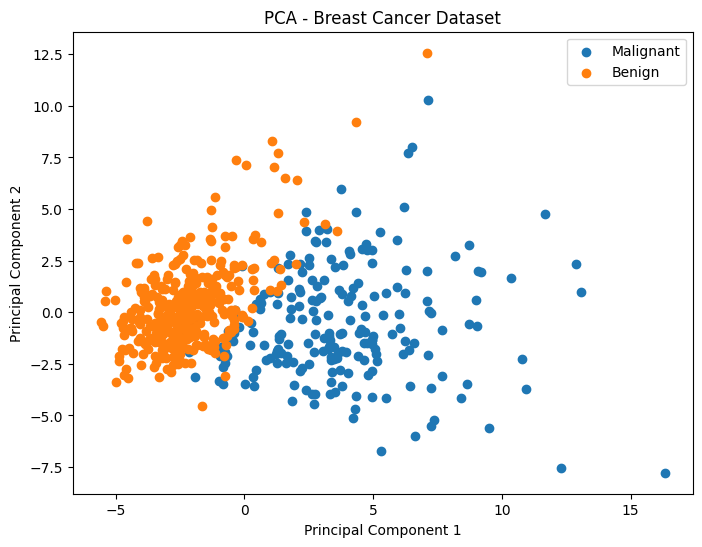

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Malignant"
)

plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Benign"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Breast Cancer Dataset")
plt.legend()

plt.show()

In [12]:
pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

print(cumulative_variance)

[0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]


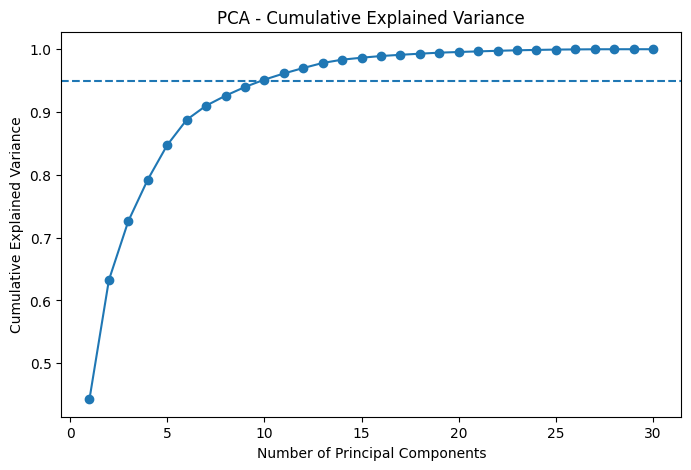

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.axhline(y=0.95, linestyle="--")

plt.show()

In [ ]:
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components required for 95% variance:", n_components)

Components required for 95% variance: 10


In [14]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("t-SNE shape:", X_tsne.shape)

Original shape: (569, 30)
t-SNE shape: (569, 2)


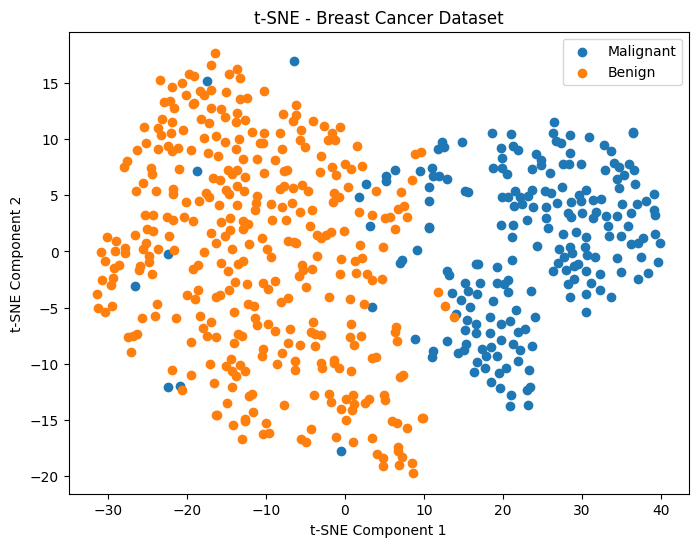

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[y == 0, 0],
    X_tsne[y == 0, 1],
    label="Malignant"
)

plt.scatter(
    X_tsne[y == 1, 0],
    X_tsne[y == 1, 1],
    label="Benign"
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE - Breast Cancer Dataset")
plt.legend()

plt.show()

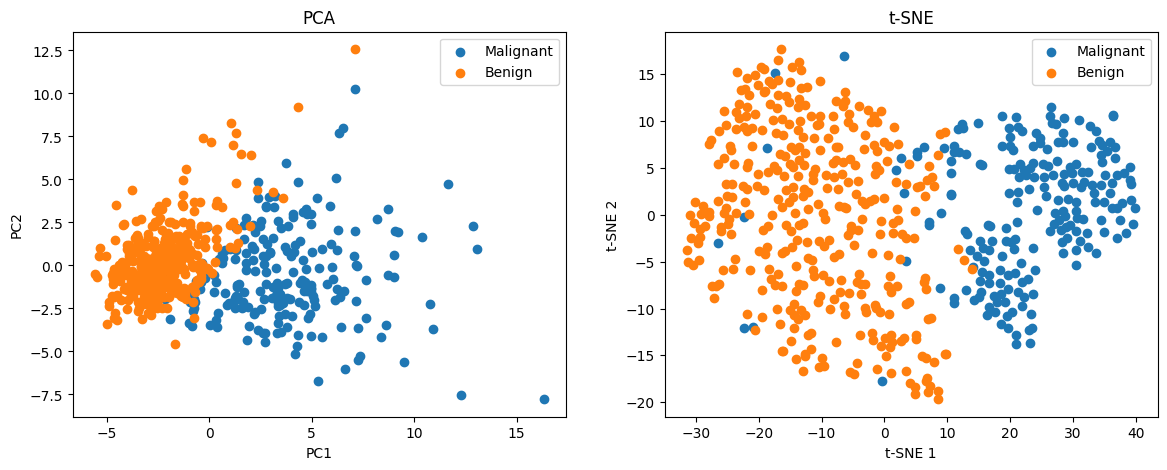

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA
axes[0].scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Malignant"
)

axes[0].scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Benign"
)

axes[0].set_title("PCA")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

# t-SNE
axes[1].scatter(
    X_tsne[y == 0, 0],
    X_tsne[y == 0, 1],
    label="Malignant"
)

axes[1].scatter(
    X_tsne[y == 1, 0],
    X_tsne[y == 1, 1],
    label="Benign"
)

axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
axes[1].legend()

plt.show()